# code_162 · Self-supervised sensor objectives and augmentation validity

**Book:** section 31.2. A self-contained limited-label learning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_31_GUIDE.md), [run evidence](../CHAPTER_31_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_162).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json,copy,hashlib
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=4262;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 4262


<a id="self-supervised-pretext-and-downstream"></a>
 ## Compare objectives through a separate labelled task
 Generate 256 source buildings, 64 development buildings and 64 final buildings, two sensor windows per building. Shared building amplitude/frequency creates within-group dependence. Each window has 32 values; the downstream target is a constructed amplitude measurement. Pretrain original encoders on source windows only with masked reconstruction, denoising, contrastive small-noise views, contrastive amplitude-normalized views or temporal prediction of the last eight values. Each method uses 600 Adam updates with batch 64 and the same initial encoder. A random encoder and raw features are controls. Freeze each encoder and fit a ridge predictor from 16 or 64 source-building labels (one window per labelled building); the separate 128 development outcomes select between two ridge penalties. All 128 final windows remain outside pretraining and selection. These original mechanisms are not full VIME or SimCLR reproductions.


,representation,labelled_source_buildings,source_labels,development_labels,selected_ridge_alpha,development_MAE,final_MAE
0,Random,16,16,128,0.1,0.078034,0.091650
1,Random,64,64,128,0.1,0.066466,0.086449
2,Masked,16,16,128,0.1,0.066501,0.075224
3,Masked,64,64,128,0.1,0.058643,0.068310
4,Denoising,16,16,128,0.1,0.044996,0.042667
5,Denoising,64,64,128,0.1,0.029328,0.031745
6,Contrastive noise,16,16,128,0.1,0.137151,0.138207
7,Contrastive noise,64,64,128,0.1,0.105939,0.105892
8,Contrastive normalized,16,16,128,0.1,0.105043,0.119608
9,Contrastive normalized,64,64,128,10.0,0.082989,0.100727


Pretext first/last losses (different scales): {'Random': [], 'Masked': [1.0527499607090558, 0.05461262993132964], 'Denoising': [1.0522317163906942, 0.006645578365959203], 'Contrastive noise': [3.58472983968971, 1.9049148764381651], 'Contrastive normalized': [3.902171620710043, 2.0642773384689144], 'Temporal': [1.1204896531325033, 0.006397494742693507]}


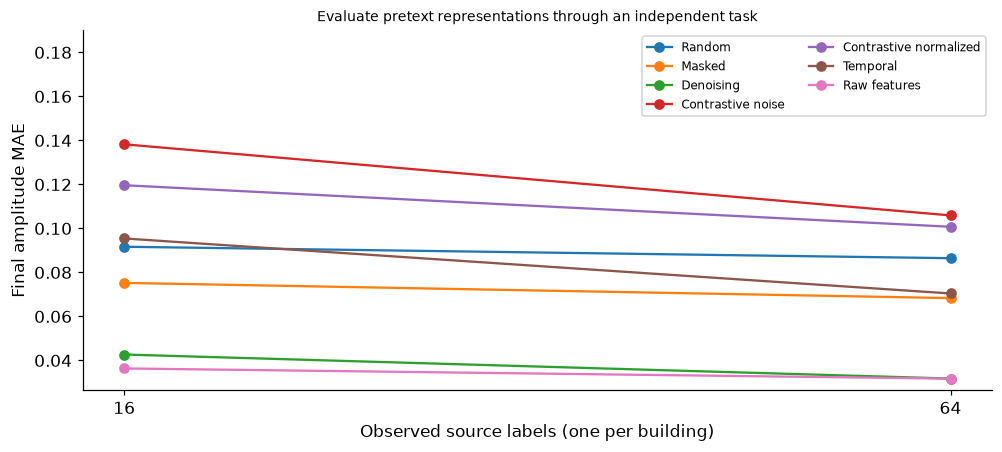

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
def sensor_cohort(n,offset):
    g=np.repeat(np.arange(offset,offset+n),2);a=np.repeat(rng.uniform(.4,2.0,n),2);freq=np.repeat(rng.uniform(.8,1.2,n),2);phase=rng.uniform(-.3,.3,2*n);t=np.linspace(0,2*np.pi,32);raw=a[:,None]*np.sin(freq[:,None]*t+phase[:,None])+rng.normal(0,.035,(2*n,32));return raw,a,g
sx,sy,sg=sensor_cohort(256,0);dx,dy,dg=sensor_cohort(64,1000);fx,fy,fg=sensor_cohort(64,2000);scaler=StandardScaler().fit(sx);S=scaler.transform(sx);D=scaler.transform(dx);F=scaler.transform(fx);assert not set(sg)&(set(dg)|set(fg)) and not set(dg)&set(fg)
def encoder():return nn.Sequential(nn.Linear(32,32),nn.Tanh(),nn.Linear(32,8))
torch.manual_seed(SEED);initial=copy.deepcopy(encoder().state_dict());encoders={};losses={};Z=torch.tensor(S)
for method in ['Random','Masked','Denoising','Contrastive noise','Contrastive normalized','Temporal']:
    torch.manual_seed(SEED);enc=encoder();enc.load_state_dict(initial);decoder=nn.Linear(8,32);projection=nn.Linear(8,8);optimizer=torch.optim.Adam(list(enc.parameters())+list(decoder.parameters())+list(projection.parameters()),lr=.003);generator=torch.Generator().manual_seed(SEED+3);trace=[]
    for step in range(0 if method=='Random' else 600):
        ids=torch.randint(len(S),(64,),generator=generator);clean=Z[ids];noise=torch.randn((64,32),generator=generator)*.05
        if method=='Masked':
            mask=torch.rand((64,32),generator=generator)<.3;corrupted=clean.masked_fill(mask,0);pred=decoder(enc(corrupted));loss=((pred-clean)**2)[mask].mean()
        elif method=='Denoising':loss=nn.functional.mse_loss(decoder(enc(clean+noise)),clean)
        elif method=='Temporal':
            prefix=clean.clone();prefix[:,-8:]=0;loss=nn.functional.mse_loss(decoder(enc(prefix))[:,-8:],clean[:,-8:])
        else:
            view1=clean+noise;view2=clean+torch.randn((64,32),generator=generator)*.05
            if method=='Contrastive normalized':
                raw1=view1*torch.tensor(scaler.scale_)+torch.tensor(scaler.mean_);raw2=view2*torch.tensor(scaler.scale_)+torch.tensor(scaler.mean_);view1=(raw1/(raw1.square().mean(1,keepdim=True).sqrt()+1e-8)-torch.tensor(scaler.mean_))/torch.tensor(scaler.scale_);view2=(raw2/(raw2.square().mean(1,keepdim=True).sqrt()+1e-8)-torch.tensor(scaler.mean_))/torch.tensor(scaler.scale_)
            h=nn.functional.normalize(projection(enc(torch.cat([view1,view2]))),dim=1);similarity=h@h.T/.2;similarity=similarity.masked_fill(torch.eye(128,dtype=torch.bool),-1e9);positive=(torch.arange(128)+64)%128;loss=nn.functional.cross_entropy(similarity,positive)
        optimizer.zero_grad();loss.backward();optimizer.step()
        if step in [0,599]:trace.append(float(loss.detach()))
    enc.eval();encoders[method]=enc;losses[method]=trace
def represent(enc,x):
    with torch.no_grad():return enc(torch.tensor(x)).numpy()
representations={name:(represent(enc,S),represent(enc,D),represent(enc,F)) for name,enc in encoders.items()};representations['Raw features']=(S,D,F);rows=[];source_building_order=np.arange(256);chosen_ids=np.array([np.flatnonzero(sg==i)[0] for i in source_building_order]);assert len(set(sg[chosen_ids]))==256
for name,(xs,xd,xf) in representations.items():
    for budget in [16,64]:
        ids=chosen_ids[:budget];candidates=[]
        for alpha in [.1,10.]:
            model=make_pipeline(StandardScaler(),Ridge(alpha=alpha)).fit(xs[ids],sy[ids]);score=float(np.mean(np.abs(model.predict(xd)-dy)));candidates.append((score,alpha,model))
        dev,alpha,model=min(candidates,key=lambda r:r[0]);prediction=model.predict(xf);rows.append({'representation':name,'labelled_source_buildings':budget,'source_labels':budget,'development_labels':128,'selected_ridge_alpha':alpha,'development_MAE':dev,'final_MAE':float(np.mean(np.abs(prediction-fy)))})
template=np.sin(np.linspace(0,2*np.pi,32));low=.6*template;high=1.8*template;low_unit=low/np.sqrt(np.mean(low**2));high_unit=high/np.sqrt(np.mean(high**2));np.testing.assert_allclose(low_unit,high_unit,atol=1e-14);assert abs(.6-1.8)>1
RESULTS.update(source_buildings=256,source_unlabelled_windows=512,development_buildings=64,development_labels=128,final_buildings=64,final_windows=128,pretraining_updates_per_nonrandom_objective=600,pretraining_batch=64,pretraining_learning_rate=.003,embedding_dimensions=8,metrics=rows,pretext_first_last_losses=losses,augmentation_target_collision=True,collision_amplitudes=[.6,1.8],final_inputs_admitted_to_pretraining=False);display(pd.DataFrame(rows));print('Pretext first/last losses (different scales):',losses)
fig,ax=plt.subplots(figsize=(9,4))
for name in representations:
    rr=[r for r in rows if r['representation']==name];ax.plot([r['source_labels'] for r in rr],[r['final_MAE'] for r in rr],marker='o',label=name)
ax.set(xticks=[16,64],xlabel='Observed source labels (one per building)',ylabel='Final amplitude MAE',title='Evaluate pretext representations through an independent task');ax.set_ylim(top=.19);ax.legend(fontsize=8,ncol=2);plt.show()


<a id="augmentation-and-identifiability"></a>
 ## A pretext success can discard the downstream target
 Amplitude normalization maps the exact signals 0.6 sin(t)and 1.8 sin(t)to the same unit-RMS curve even though their amplitude targets differ. No predictor using only that normalized curve can distinguish the pair. This exact collision audits an augmentation assumption independently of whichever finite-sample downstream model happens to win. Noise views preserve amplitude approximately under the constructed sensor model; they are not automatically valid for every damage target. Contrastive batches can also contain two windows from one building as nominal negatives. Pretext loss values have different units and meanings and are not ranked against each other. Temporal pretraining predicts values within a training window; downstream assessment is an amplitude task with the full admitted window, not a future forecast.


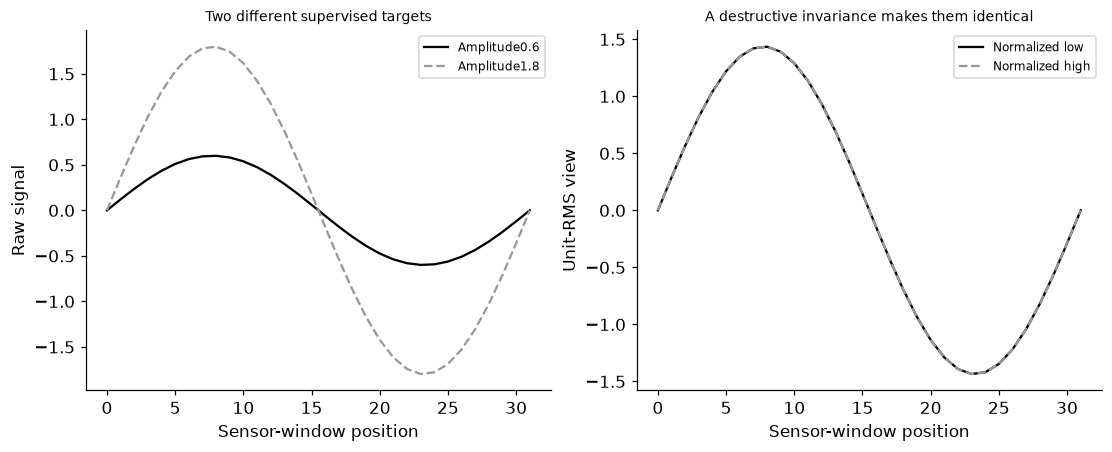

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));tt=np.arange(32);axes[0].plot(tt,low,color='black',label='Amplitude0.6');axes[0].plot(tt,high,color='.6',linestyle='--',label='Amplitude1.8');axes[0].set(xlabel='Sensor-window position',ylabel='Raw signal',title='Two different supervised targets');axes[0].legend(fontsize=8);axes[1].plot(tt,low_unit,color='black',label='Normalized low');axes[1].plot(tt,high_unit,color='.6',linestyle='--',label='Normalized high');axes[1].set(xlabel='Sensor-window position',ylabel='Unit-RMS view',title='A destructive invariance makes them identical');axes[1].legend(fontsize=8);plt.show()
assert len(rows)==14 and all(r['source_labels'] in [16,64] for r in rows) and np.isfinite([r['final_MAE'] for r in rows]).all()


In [4]:
summary={'example_id':'code_162','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual masked denoising contrastive and temporal pretraining', 'frozen representation evaluation at two downstream label budgets', 'random encoder and raw numeric controls with development-only ridge selection', 'source-only feature transforms and whole-building final isolation', 'destructive amplitude invariance tested with an exact target collision'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual masked denoising contrastive and temporal pretraining", "frozen representation evaluation at two downstream label budgets", "random encoder and raw numeric controls with development-only ridge selection", "source-only feature transforms and whole-building final isolation", "destructive amplitude invariance tested with an exact target collision"], "elapsed_seconds": 1.643, "example_id": "code_162", "hardware": "Darwin arm64 CPU", "results": {"augmentation_target_collision": true, "collision_amplitudes": [0.6, 1.8], "development_buildings": 64, "development_labels": 128, "embedding_dimensions": 8, "final_buildings": 64, "final_inputs_admitted_to_pretraining": false, "final_windows": 128, "metrics": [{"development_MAE": 0.07803358573071843, "development_labels": 128, "final_MAE": 0.09164963724625422, "labelled_source_buildings": 16, "representation": "Random", "selected_ridge_alpha": 0.1, "source_labels": 16}, {"development_MAE": 0